In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Tổng hợp các lời gọi LLM và số token đã tiêu hao

In [2]:
from pathlib import Path

# Thư mục chứa 4 file CSV
input_dir = Path(r"D:\INT3011E\AgentOccam\metrics")

# Đường dẫn file kết quả
output_file = Path(
    r"D:\INT3011E\AgentOccam-Trajectories\AgentOccam_Qwen14bShopping\llm_calls_merged.csv"
)

files = [
    "llm_calls.csv",
    "llm_calls(1).csv",
    "llm_calls(2).csv",
    "llm_calls(3).csv",
    "llm_calls(4).csv"
]

df = pd.concat(
    [pd.read_csv(input_dir / file) for file in files],
    ignore_index=True,
)

# Chuyển task_id sang số để tránh thứ tự kiểu chuỗi: 1, 10, 2
df["task_id"] = pd.to_numeric(df["task_id"], errors="raise")

# Sắp xếp tăng dần, giữ nguyên thứ tự các lần gọi trong cùng task
df = df.sort_values("task_id", kind="stable").reset_index(drop=True)

output_file.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_file, index=False, encoding="utf-8-sig")

print(f"Đã gộp {len(files)} file, tổng cộng {len(df)} dòng.")
print(f"Lưu tại: {output_file}")

Đã gộp 5 file, tổng cộng 197 dòng.
Lưu tại: D:\INT3011E\AgentOccam-Trajectories\AgentOccam_Qwen14bShopping\llm_calls_merged.csv


# 2. Phân tích tỉ lệ thành công

## 2.1: Tỷ lệ thành công tổng thể

In [3]:
summary_dir = Path(
    r"D:\INT3011E\AgentOccam-Trajectories\AgentOccam_Qwen14bShopping"
)

summary = pd.read_csv(summary_dir / "summary.csv")
summary = summary.sort_values("task_id", kind="stable").reset_index(drop=True)
summary.head()

,task,task_id,model,type,logfile,done,reward,success,num_actions,task_seconds
0,config_files/tasks/21.json,21,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,0.8,1.0,2,88.5591
1,config_files/tasks/22.json,22,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,88.2813
2,config_files/tasks/23.json,23,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,506.7483
3,config_files/tasks/24.json,24,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,81.3600
4,config_files/tasks/25.json,25,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,107.0506


In [4]:
summary["success"] = pd.to_numeric(summary["success"], errors="raise")

total = len(summary)
success_count = (summary["success"] == 1).sum()
failure_count = (summary["success"] == 0).sum()
other_count = total - success_count - failure_count

print(f"Tổng số task: {total}")
print(f"Số task thành công: {success_count}")
print(f"Số task thất bại: {failure_count}")
print(f"Số task khác: {other_count}")
print(f"Tỷ lệ thành công: {success_count / total:.2%}")

Tổng số task: 60
Số task thành công: 28
Số task thất bại: 32
Số task khác: 0
Tỷ lệ thành công: 46.67%


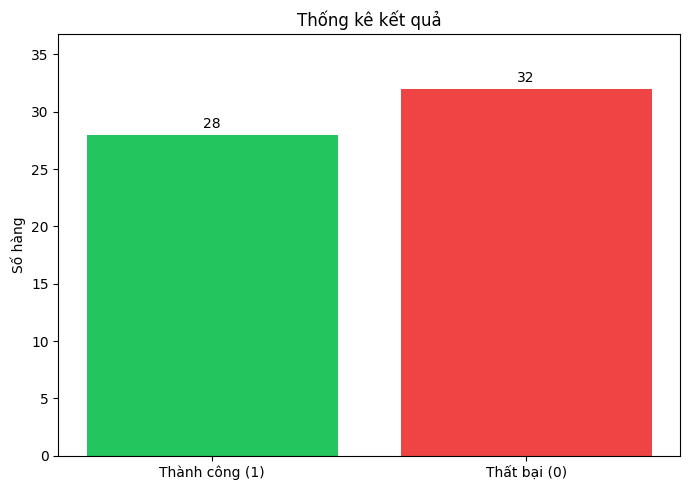

In [5]:
# Vẽ biểu đồ cột
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Thành công (1)", "Thất bại (0)"],
    [success_count, failure_count],
    color=["#22c55e", "#ef4444"],
)

ax.bar_label(bars, padding=3)
ax.set_ylabel("Số hàng")
ax.set_title("Thống kê kết quả")
ax.set_ylim(0, max(success_count, failure_count, 1) * 1.15)
ax.yaxis.get_major_locator().set_params(integer=True)

plt.tight_layout()
plt.show()

## 2.2: Tỷ lệ thành công với từng loại task

In [6]:
import json
from pathlib import Path
import pandas as pd

tasks_dir = Path(r"D:\INT3011E\AgentOccam\config_files\tasks")
summary_dir = Path(
    r"D:\INT3011E\AgentOccam-Trajectories\AgentOccam_Qwen14bShopping"
)

# 1. Đọc các file JSON, tạo ánh xạ task_id -> intent_template
task_types = {}

for json_file in sorted(tasks_dir.glob("*.json")):
    with json_file.open("r", encoding="utf-8-sig") as f:
        task = json.load(f)
    if task.get("task_id") == "Allrecipes--3":
        continue  # Bỏ qua task Allrecipes--3 vì không có trong summary
    task_id = int(task["task_id"])
    template = task["intent_template"]

    # Tránh ghi đè âm thầm nếu có các file trùng ID nhưng khác loại
    if task_id in task_types and task_types[task_id] != template:
        raise ValueError(f"Task ID {task_id} có nhiều intent_template khác nhau.")

    task_types[task_id] = template

# 2. Đọc bảng summary
summary = pd.read_csv(summary_dir / "summary.csv")
summary["task_id"] = pd.to_numeric(summary["task_id"], errors="raise").astype("Int64")

# 3. Thêm task_type theo task_id
summary["task_type"] = summary["task_id"].map(task_types)

# Thông báo những task không tìm thấy loại
missing_ids = summary.loc[summary["task_type"].isna(), "task_id"].unique().tolist()
if missing_ids:
    print(f"Cảnh báo: chưa tìm thấy task_type cho các task: {missing_ids}")

# 4. Sắp xếp theo task_id rồi lưu thành file mới
summary = summary.sort_values("task_id", kind="stable").reset_index(drop=True)

output_file = summary_dir / "final_summary.csv"
summary.to_csv(output_file, index=False, encoding="utf-8-sig")

print(f"Đã lưu: {output_file}")
print(f"Tổng số hàng: {len(summary)}")
print(f"Số loại task trong summary: {summary['task_type'].nunique()}")

Đã lưu: D:\INT3011E\AgentOccam-Trajectories\AgentOccam_Qwen14bShopping\final_summary.csv
Tổng số hàng: 60
Số loại task trong summary: 16


In [7]:
summary.head()

,task,task_id,model,type,logfile,done,reward,success,num_actions,task_seconds,task_type
0,config_files/tasks/21.json,21,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,0.8,1.0,2,88.5591,"List out reviewers, if exist, who mention abou..."
1,config_files/tasks/22.json,22,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,88.2813,"List out reviewers, if exist, who mention abou..."
2,config_files/tasks/23.json,23,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,506.7483,"List out reviewers, if exist, who mention abou..."
3,config_files/tasks/24.json,24,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,81.3600,"List out reviewers, if exist, who mention abou..."
4,config_files/tasks/25.json,25,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,107.0506,"List out reviewers, if exist, who mention abou..."


In [8]:
from pathlib import Path
import pandas as pd

folder = Path(
    r"D:\INT3011E\AgentOccam-Trajectories\AgentOccam_Qwen14bShopping"
)
df = pd.read_csv(folder / "final_summary.csv")

df["success"] = pd.to_numeric(df["success"], errors="raise")

# Đảm bảo không bỏ sót giá trị thiếu hoặc khác 0/1 khi tính tỷ lệ
if not df["success"].isin([0, 1]).all():
    raise ValueError("Cột success có giá trị thiếu hoặc khác 0/1.")

stats = (
    df.groupby("task_type", dropna=False)
    .agg(
        total_tasks=("success", "size"),
        successful_tasks=("success", "sum"),
        success_rate_percent=("success", "mean"),
    )
    .reset_index()
)

stats["success_rate_percent"] = (
    stats["success_rate_percent"] * 100
).round(2)

# stats = stats.sort_values("success_rate_percent", ascending=False)

print(stats.to_string(index=False))

# Lưu bảng thống kê
stats.to_csv(
    folder / "task_type_stats.csv",
    index=False,
    encoding="utf-8-sig",
)

stats.head()


                                                                                                            task_type  total_tasks  successful_tasks  success_rate_percent
                                                             Get the order number of my most recent {{status}} order             5               3.0                 60.00
                                                            How much I spent on {{category}} shopping during {{time}}            5               0.0                  0.00
I am doing a market survey for one stop market, show me the most expensive product from {{product_category}} category            5               0.0                  0.00
        I have a lot of Nintendo Switch game cards now, help me find the best storage option to fit all {{num}} cards            5               2.0                 40.00
                                      I have jaw bruxism problem, show me something that could alleviate the problem.            1               

,task_type,total_tasks,successful_tasks,success_rate_percent
0,Get the order number of my most recent {{statu...,5,3.0,60.0
1,How much I spent on {{category}} shopping duri...,5,0.0,0.0
2,I am doing a market survey for one stop market...,5,0.0,0.0
3,I have a lot of Nintendo Switch game cards now...,5,2.0,40.0
4,"I have jaw bruxism problem, show me something ...",1,1.0,100.0


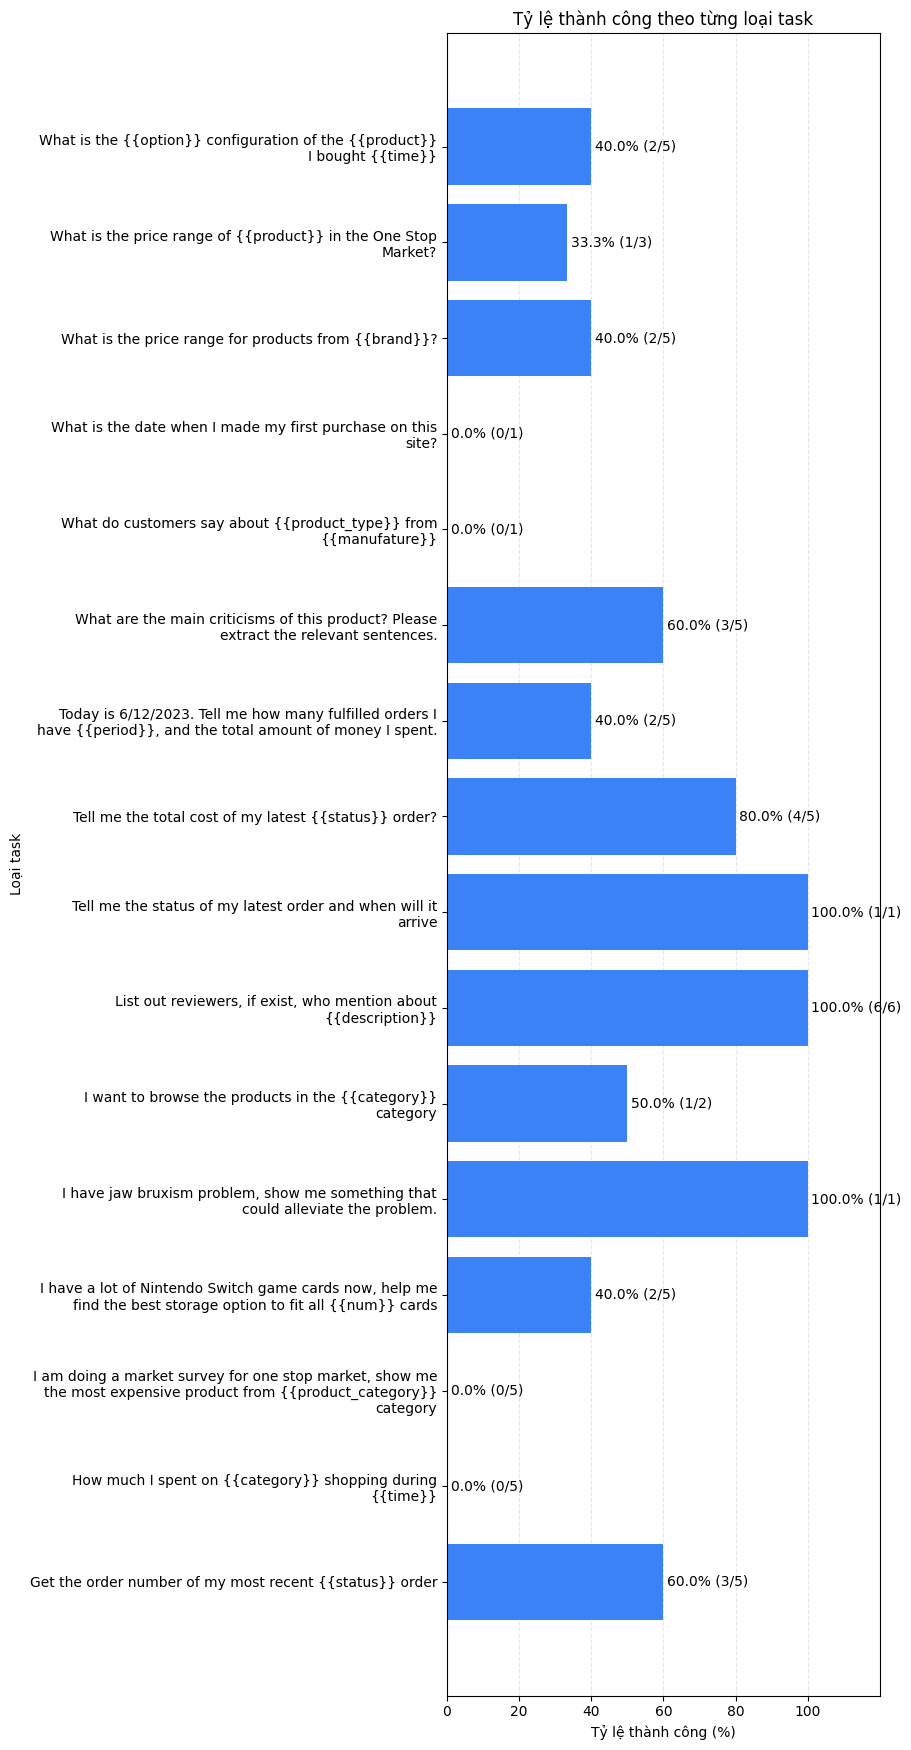

In [9]:
import matplotlib.pyplot as plt
import textwrap

# plot_data = stats.sort_values("success_rate_percent", ascending=True)
plot_data = stats

labels = [
    textwrap.fill(str(task_type), width=55)
    for task_type in plot_data["task_type"]
]

fig, ax = plt.subplots(
    figsize=(9, max(5, len(plot_data) * 1.1))
)

bars = ax.barh(
    labels,
    plot_data["success_rate_percent"],
    color="#3b82f6",
)

# Hiển thị tỷ lệ và số task thành công / tổng số task
for bar, (_, row) in zip(bars, plot_data.iterrows()):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{row['success_rate_percent']:.1f}% "
        f"({int(row['successful_tasks'])}/{int(row['total_tasks'])})",
        va="center",
        fontsize=10,
    )

ax.set_xlim(0, 120)  # Chừa khoảng trống cho nhãn
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Tỷ lệ thành công (%)")
ax.set_ylabel("Loại task")
ax.set_title("Tỷ lệ thành công theo từng loại task")
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

# Lưu ảnh vào cùng thư mục final_summary.csv
plt.savefig(folder / "task_type_success_rate.png", dpi=300, bbox_inches="tight")
plt.show()

# 2.3: Số token và thời gian llm thực thi

### 2.3.1: Theo từng task

In [10]:
folder = Path(
    r"D:\INT3011E\AgentOccam-Trajectories\AgentOccam_Qwen14bShopping"
)
df = pd.read_csv(folder / "llm_calls_merged.csv")
df = df.drop(columns=["timestamp"])

stats = (
    df.groupby("task_id", dropna=False)
    .agg(
        input_tokens=("input_tokens", "sum"),
        output_tokens=("output_tokens", "sum"),
        total_tokens=("total_tokens", "sum"),
        llm_seconds=("llm_seconds", "sum"),
    )
    .reset_index()
)


# stats = stats.sort_values("success_rate_percent", ascending=False)

output_file = folder / "llm_calls_summary.csv"
stats.to_csv(output_file, index=False, encoding="utf-8-sig")

stats.head()

,task_id,input_tokens,output_tokens,total_tokens,llm_seconds
0,21,6289,1115,7404,18.3204
1,22,6468,1088,7556,17.9761
2,23,6263,26505,32768,433.0136
3,24,4174,995,5169,15.4331
4,25,9050,1113,10163,19.3141


In [11]:
final_summary = pd.read_csv(folder / "final_summary.csv")

summary_merged = pd.merge(
    final_summary,
    stats,
    on="task_id",
    how="left",
    suffixes=("_summary", "_llm")
)

final_output_file = folder / "final_summary_with_llm_calls.csv"
summary_merged.to_csv(final_output_file, index=False, encoding="utf-8-sig")

summary_merged.head()

,task,task_id,model,type,logfile,done,reward,success,num_actions,task_seconds,task_type,input_tokens,output_tokens,total_tokens,llm_seconds
0,config_files/tasks/21.json,21,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,0.8,1.0,2,88.5591,"List out reviewers, if exist, who mention abou...",6289,1115,7404,18.3204
1,config_files/tasks/22.json,22,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,88.2813,"List out reviewers, if exist, who mention abou...",6468,1088,7556,17.9761
2,config_files/tasks/23.json,23,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,506.7483,"List out reviewers, if exist, who mention abou...",6263,26505,32768,433.0136
3,config_files/tasks/24.json,24,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,81.3600,"List out reviewers, if exist, who mention abou...",4174,995,5169,15.4331
4,config_files/tasks/25.json,25,qwen3-14b,AgentOccam,AgentOccam-Trajectories/AgentOccam_Qwen14bShop...,True,1.0,1.0,2,107.0506,"List out reviewers, if exist, who mention abou...",9050,1113,10163,19.3141


số token của các task thành công/thất bại

In [12]:
df = pd.read_csv(folder / "final_summary_with_llm_calls.csv")

success_tokens = (
    df.groupby("success", dropna=False)
    .agg(
        input_tokens=("input_tokens", "sum"),
        output_tokens=("output_tokens", "sum"),
        total_tokens=("total_tokens", "sum"),
        llm_seconds=("llm_seconds", "sum"),
        task_seconds=("task_seconds", "sum"),
        num_actions=("num_actions", "sum"),
        avg_input_tokens=("input_tokens", "mean"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_total_tokens=("total_tokens", "mean"),
        avg_llm_seconds=("llm_seconds", "mean"),
        avg_task_seconds=("task_seconds", "mean"),
        avg_num_actions=("num_actions", "mean")
    )
    .reset_index()
)

success_tokens.head()

,success,input_tokens,output_tokens,total_tokens,llm_seconds,task_seconds,num_actions,avg_input_tokens,avg_output_tokens,avg_total_tokens,avg_llm_seconds,avg_task_seconds,avg_num_actions
0,0.0,383641,157618,541259,2547.6585,6407.1028,111,11988.781250,4925.562500,16914.343750,79.614328,200.221962,3.468750
1,1.0,241498,121346,362844,1952.8061,4483.9038,81,8624.928571,4333.785714,12958.714286,69.743075,160.139421,2.892857


plot theo histogram

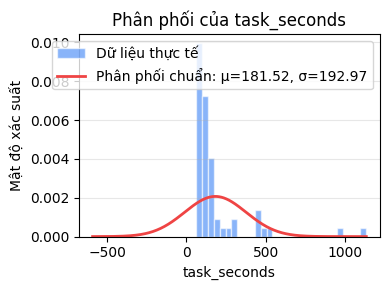

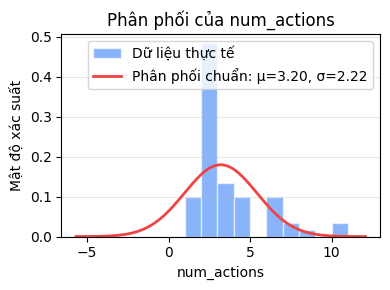

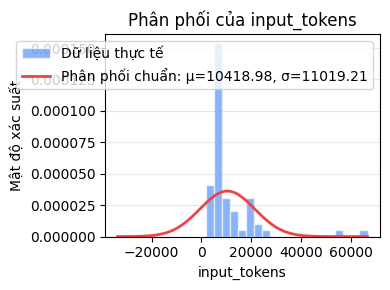

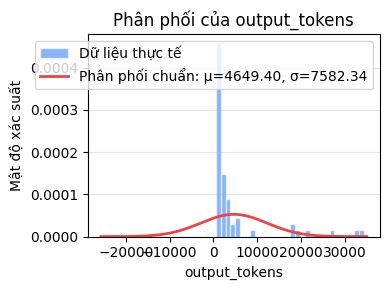

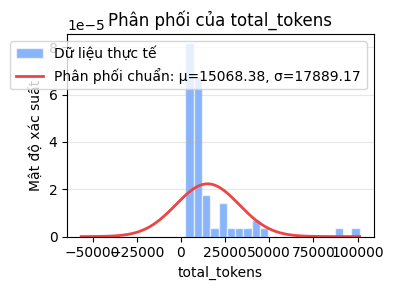

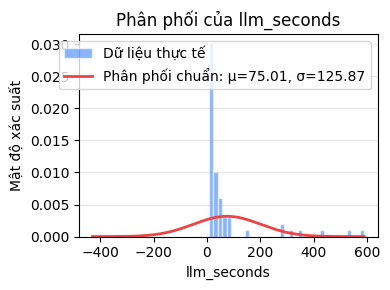

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

columns = ["task_seconds", "num_actions", "input_tokens", "output_tokens", "total_tokens", "llm_seconds"]

for column in columns:
    data = (
        pd.to_numeric(df[column], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if len(data) < 2 or data.nunique() < 2:
        print(f"Bỏ qua {column}: không đủ dữ liệu hoặc các giá trị giống nhau.")
        continue

    mu, sigma = norm.fit(data)

    # Tạo biểu đồ riêng cho mỗi cột
    fig, ax = plt.subplots(figsize=(4, 3))

    ax.hist(
        data,
        bins="auto",
        density=True,
        alpha=0.6,
        color="#3b82f6",
        edgecolor="white",
        label="Dữ liệu thực tế",
    )

    x = np.linspace(
        min(data.min(), mu - 4 * sigma),
        max(data.max(), mu + 4 * sigma),
        500,
    )

    ax.plot(
        x,
        norm.pdf(x, mu, sigma),
        color="#ef4444",
        linewidth=2,
        label=f"Phân phối chuẩn: μ={mu:.2f}, σ={sigma:.2f}",
    )

    ax.set_title(f"Phân phối của {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Mật độ xác suất")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

### 2.3.2: Theo từng loại task

In [14]:
df = pd.read_csv(folder / "final_summary_with_llm_calls.csv")
task_types_stats = pd.read_csv(folder / "task_type_stats.csv")

success_tokens = (
    df.groupby("task_type", dropna=False)
    .agg(
        input_tokens=("input_tokens", "sum"),
        output_tokens=("output_tokens", "sum"),
        total_tokens=("total_tokens", "sum"),
        llm_seconds=("llm_seconds", "sum"),
        task_seconds=("task_seconds", "sum"),
        num_actions=("num_actions", "sum"),
        avg_input_tokens=("input_tokens", "mean"),
        avg_output_tokens=("output_tokens", "mean"),
        avg_total_tokens=("total_tokens", "mean"),
        avg_llm_seconds=("llm_seconds", "mean"),
        avg_task_seconds=("task_seconds", "mean"),
        avg_num_actions=("num_actions", "mean")
    )
    .reset_index()
)

task_types_stats_merged = pd.merge(
    task_types_stats,
    success_tokens,
    how="left",
    on="task_type",
)

final_output_file = folder / "task_type_stats.csv"
task_types_stats_merged.to_csv(final_output_file, index=False, encoding="utf-8-sig")

success_tokens.head()

,task_type,input_tokens,output_tokens,total_tokens,llm_seconds,task_seconds,num_actions,avg_input_tokens,avg_output_tokens,avg_total_tokens,avg_llm_seconds,avg_task_seconds,avg_num_actions
0,Get the order number of my most recent {{statu...,25493,6217,31710,97.4119,464.7792,10,5098.6,1243.4,6342.0,19.48238,92.95584,2.0
1,How much I spent on {{category}} shopping duri...,46040,12734,58774,198.6869,662.6690,16,9208.0,2546.8,11754.8,39.73738,132.53380,3.2
2,I am doing a market survey for one stop market...,152806,90546,243352,1504.3231,2787.7303,31,30561.2,18109.2,48670.4,300.86462,557.54606,6.2
3,I have a lot of Nintendo Switch game cards now...,75343,17989,93332,283.7933,922.7910,23,15068.6,3597.8,18666.4,56.75866,184.55820,4.6
4,"I have jaw bruxism problem, show me something ...",22981,17671,40652,286.9464,435.4612,7,22981.0,17671.0,40652.0,286.94640,435.46120,7.0


In [15]:
df = pd.read_csv(folder / "task_type_stats.csv")
df.head()

,task_type,total_tasks,successful_tasks,success_rate_percent,input_tokens,output_tokens,total_tokens,llm_seconds,task_seconds,num_actions,avg_input_tokens,avg_output_tokens,avg_total_tokens,avg_llm_seconds,avg_task_seconds,avg_num_actions
0,Get the order number of my most recent {{statu...,5,3.0,60.0,25493,6217,31710,97.4119,464.7792,10,5098.6,1243.4,6342.0,19.48238,92.95584,2.0
1,How much I spent on {{category}} shopping duri...,5,0.0,0.0,46040,12734,58774,198.6869,662.6690,16,9208.0,2546.8,11754.8,39.73738,132.53380,3.2
2,I am doing a market survey for one stop market...,5,0.0,0.0,152806,90546,243352,1504.3231,2787.7303,31,30561.2,18109.2,48670.4,300.86462,557.54606,6.2
3,I have a lot of Nintendo Switch game cards now...,5,2.0,40.0,75343,17989,93332,283.7933,922.7910,23,15068.6,3597.8,18666.4,56.75866,184.55820,4.6
4,"I have jaw bruxism problem, show me something ...",1,1.0,100.0,22981,17671,40652,286.9464,435.4612,7,22981.0,17671.0,40652.0,286.94640,435.46120,7.0
